# **Object Detection with YOLO**

## **What Is Object Detection**

Object detection is a way of teaching computers to find and identify objects in photos or videos, similar to how your eyes and brain instantly recognize a dog, a car, or a person. The computer looks at an image as a grid of tiny colored dots (pixels) and learns to spot patterns — like specific shapes, colors, and sizes — that match objects it was trained on. Once it finds something, it draws an invisible box around it and labels it (e.g., "car" or "pedestrian" or "person" as shown in the image below). This technology powers things you use every day, like self-driving cars that spot people crossing the road, or hospital software that helps doctors detect diseases in X-rays. It works by running images through layers of a neural network — a system loosely inspired by the human brain — that gets better at recognizing things the more examples it sees.


![Object detection illustrated from image recognition and localization](https://images.datacamp.com/image/upload/v1664382700/Object_detection_illustrated_from_image_recognition_and_localization_704ca34bd8.png)


## **What Is YOLO?**

YOLO (You Only Look Once) is a fast object detection system that works by looking at an entire image just once — hence the name. Unlike older methods that scan an image  multiple times. YOLO only needs a single pass through its neural network to make all its predictions. It does this by dividing the image into regions and predicting bounding boxes and probabilities for each region. This makes it incredibly fast, which is why it's popular for real-time tasks like self-driving cars or live video surveillance. First introduced in 2015, YOLO has gone through several iterations and become one of the most popular object detection frameworks, with improvements in each version around speed and accuracy.

## **How It Works?**

### **Step 1: Grid Division**
When you feed an image into YOLO, the first thing it does is divide that image into an N×N grid (in the example image for simplicity we are taking a 4x4 grid) — think of it like overlaying a chessboard on top of a photo. Each cell in this grid is given a specific responsibility: if the center point of any object falls inside a particular cell, that cell "owns" the job of detecting that object. So a cell in the top-left corner won't worry about the player shoes or football in the bottom.


![Grid cells applied to image](https://images.datacamp.com/image/upload/v1664382699/Application_of_grid_cells_to_the_original_image_7d3c056d06.png)

### **Step 2: Bounding Box Prediction**
For every cell, YOLO predicts multiple bounding boxes that is rectangular outlines that try to wrap tightly around a potential object. Each box comes with five pieces of information: where its center is, how wide and tall it is, and a confidence score that reflects two things at once — how likely it is that an object actually exists there, and how well the box fits around it. A low confidence score means the model is unsure; a high one means it's strongly committed to that prediction.

![Bounding box regression](https://images.datacamp.com/image/upload/v1664382698/Bounding_box_regression_identification_f530973d75.png)

### **Step 3: IOU Filtering**
Many neighboring cells may detect the same object, YOLO ends up with a flood of overlapping boxes. To clean this up, it uses a measure called Intersection over Union (IOU) — which simply compares how much two boxes overlap relative to the total area they cover together. If two boxes are largely covering the same region, the one that fits less precisely gets discarded. This step aggressively trims down hundreds of redundant predictions.

![IOU grid selection](https://images.datacamp.com/image/upload/v1664382698/Process_of_selecting_the_best_grids_for_prediction_393ee31f11.png)

### **Step 4: Non-Maximum Suppression**
After IOU filtering, a few competing boxes may still remain for the same object. Non-Maximum Suppression (NMS) settles this by going through all remaining boxes and keeping only the one with the highest confidence score, while suppressing everything else nearby. It's the final quality check — ensuring each real-world object gets exactly one clean, well-fitted bounding box in the output.

## **Architecture**

![YOLO Architecture](https://images.datacamp.com/image/upload/v1664382694/YOLO_Architecture_from_the_original_paper_ff4e5383c0.png)

The network has 24 convolutional layers that extract features from the image, followed by 2 fully connected layers that output the final box predictions. All images are resized to 448x448 before being processed.


[Image source](https://www.datacamp.com/blog/yolo-object-detection-explained)

## **Installing Dependencies**
### **Ultralytics**

Ultralytics is the Python package behind the YOLO model family. Its latest release is YOLO26, a real-time object detection and image segmentation model built on modern deep learning and computer vision advances.

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 3.1 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 3.3 MB/s  0:00:22m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.5/911.5 kB 85.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 3.3 MB/s  0:00:16m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [ultralytics] [ultralytics]platform]


# **OpenCV Fixer**

OpenCV installed via pip occasionally has broken or missing shared library links, causing import errors at runtime despite a successful installation. `opencv-fixer` detects and repairs these broken links automatically, without reinstalling OpenCV from scratch.

Version `0.2.5` is pinned to ensure reproducibility and avoid compatibility issues with newer releases that may behave differently.


## **The Inline Script**

The second command runs a Python one-liner directly in the terminal. It imports `AutoFix` from the package and executes it immediately, triggering the repair process on the current OpenCV installation.

In [2]:
!pip install opencv-fixer==0.2.5

!python -c "from opencv_fixer import AutoFix; AutoFix()"

# **NumPy Version Pin**

NumPy is already present in the environment, but this command installs a specific older version: `1.23.4`.

The version is pinned deliberately. Ultralytics and several of its dependencies were built and tested against NumPy 1.x. NumPy 2.0 introduced breaking API changes, and running a mismatched version can cause silent errors or crashes during inference and training. Pinning to `1.23.4` ensures the entire stack operates on a compatible and stable base.

In [6]:
!pip install --upgrade numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 2.9 MB/s  0:00:05 eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.0
    Uninstalling numpy-2.1.0:
      Successfully uninstalled numpy-2.1.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
triton-kernels 1.0.0+gitbd40f349.nv26.9 requires pytest, which is not installed.
cupti-python 13.4.0 requires nvidia-cuda-cupti~=13.4, which is not installed.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


# **Running YOLO Inference**

## **Loading the Model**

`yolo11n.pt` is the nano variant of YOLO11 — the smallest and fastest in the family, chosen here for quick experimentation without requiring heavy compute. It comes pretrained on the COCO dataset, meaning it already knows how to detect 80 common object classes out of the box.

## **About YOLO11 Model Variants**

YOLO11 ships in five sizes, each trading accuracy for speed. All variants are pretrained on COCO and support the same 80 object classes.

| Variant | Best For |
|---|---|
| `yolo11n` (Nano) | Edge devices, real-time apps, low compute |
| `yolo11s` (Small) | Balanced speed and accuracy on modest hardware |
| `yolo11m` (Medium) | General-purpose deployments with decent GPU |
| `yolo11l` (Large) | High-accuracy tasks where speed is secondary |
| `yolo11x` (Extra Large) | Maximum accuracy, research and offline processing |

The nano model sits at the lightest end — 2.6M parameters — making it ideal for rapid prototyping and real-time object detection pipelines. 🚀

## **Running Inference**

Before any custom training, the model is tested on a car image to establish a baseline. The goal is to check whether the pretrained model can already detect vehicle number plates, or whether custom training on plate-specific data will be necessary. `save=True` writes the annotated output image to disk.

## **Test Image**
![White sedan car in a scenic outdoor setting](https://images.pexels.com/photos/28673504/pexels-photo-28673504.jpeg)
*Photo by Kawaljeet Dhir, via [Pexels](https://www.pexels.com/photo/white-sedan-car-in-scenic-outdoor-setting-28673504/)*

In [27]:
!apt-get update && apt-get install -y libgl1 libglib2.0-0 libxcb1

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble InRelease [256 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:5 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2211 kB]
Get:6 http://archive.ubuntu.com/ubuntu noble/multiverse amd64 Packages [331 kB]
Get:7 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1471 kB]
Get:8 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1557 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/multiverse amd64 Packages [55.6 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble/restricted amd64 Packages [117 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble/main amd64 Packages [1808 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble/universe amd64 Packages [19.3 MB]
Get:13 http://archive.ubuntu.com/ubuntu nob

In [28]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

model.predict("pexels-kawaljeet-dhir-1478113641-28673504.jpg", save=True)
   

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

image 1/1 /workspace/pexels-kawaljeet-dhir-1478113641-28673504.jpg: 384x640 1 car, 4.1ms
Speed: 38.7ms preprocess, 4.1ms inference, 11.9ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /workspace/runs/detect/predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

# **Inference Result**

The model processed the image in milliseconds and saved the annotated output to `runs/detect/predict` by default.


# **IPython**


`IPython.display` is a utility module built into Jupyter and Colab environments. `Image` is a class within it that renders an image file directly inside the notebook output cell, rather than opening an external viewer.

## **Results**

The model identified **1 car** and nothing else. No number plate was detected.

This is expected. YOLO11n was pretrained on the COCO dataset, which contains 80 general object classes. Number plate is not among them. The model has no concept of plates and therefore cannot detect them regardless of how clearly one appears in the image.

This confirms that custom training on a labeled number plate dataset is required before the model can perform the intended task.




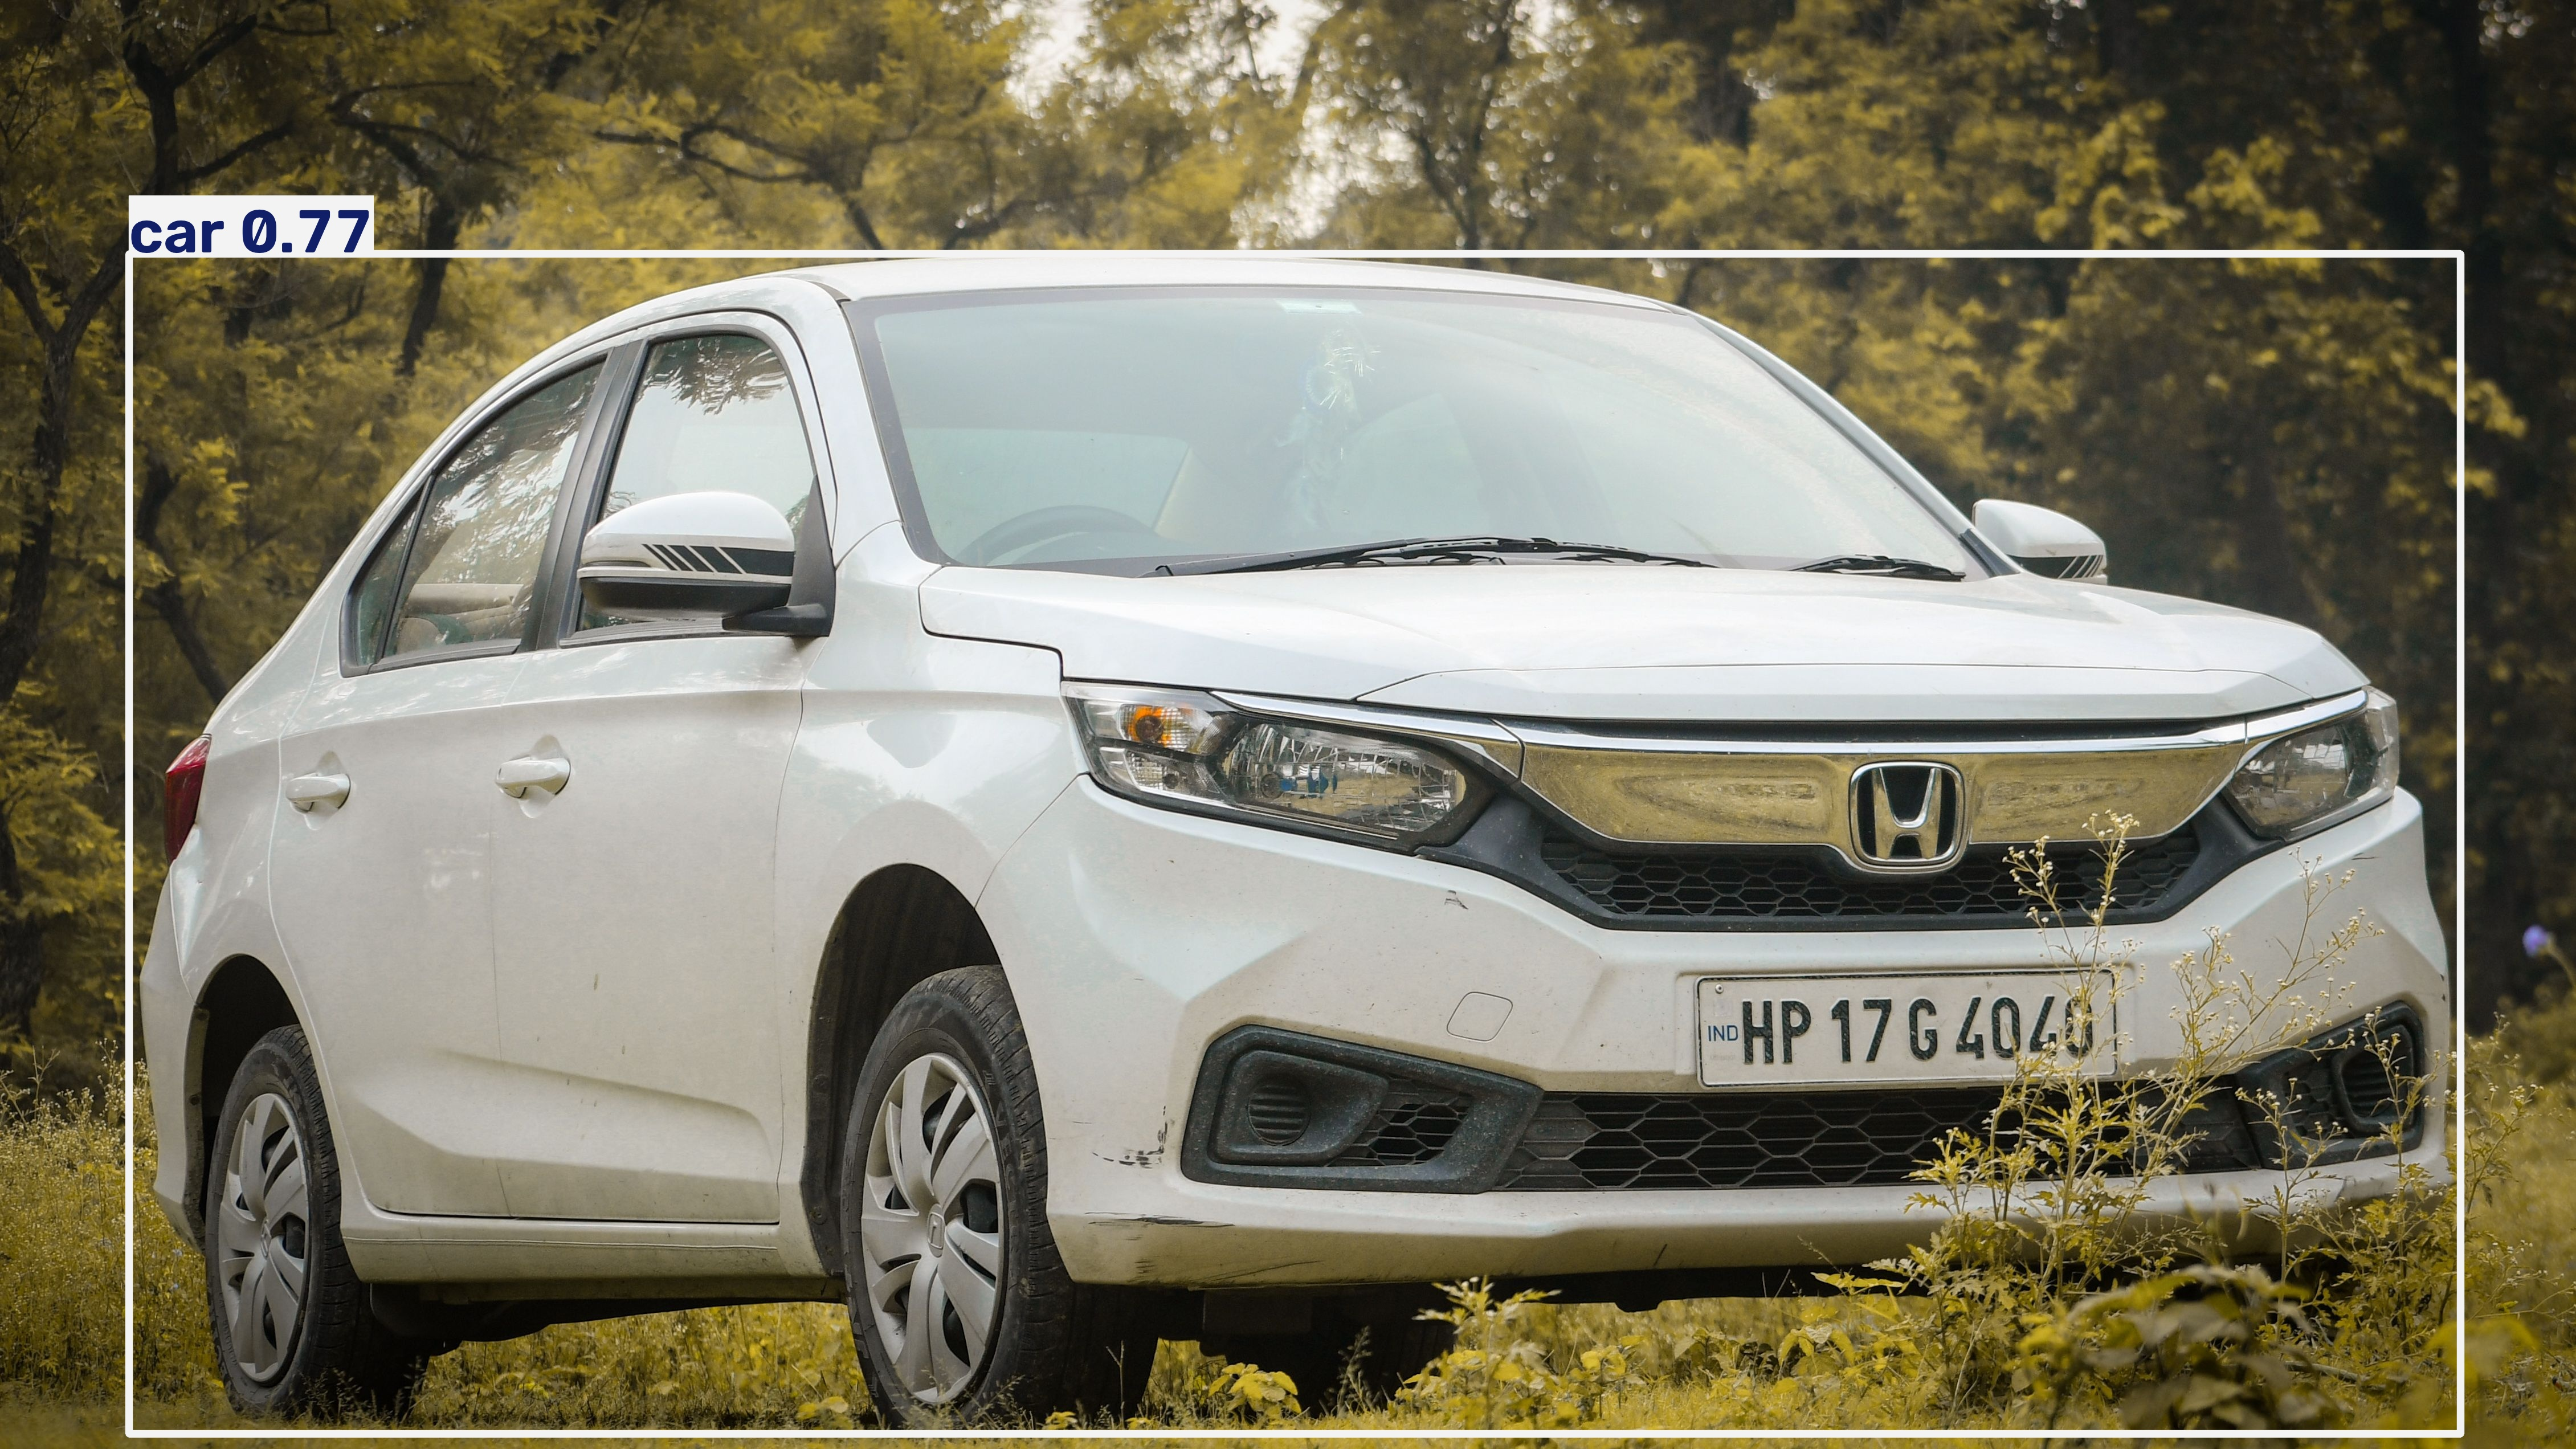

In [34]:
from IPython.display import Image
Image(filename='runs/detect/predict/pexels-kawaljeet-dhir-1478113641-28673504.jpg')

## **Test Video**
The video used here shows vehicles in city traffic, providing a realistic multi-car scene to test whether the model can detect cars across multiple frames.
*Video by [VideoLand2](https://www.storyblocks.com/video/stock/close-up-of-vehicles-stuck-in-city-traffic-in-buenos-aires-argentina-353002292) via Storyblocks, ID: SBV-353002292*

# **Loading a Test Video**
Colab notebooks cannot play video files directly from disk the way a desktop media player would. Instead, the video must be embedded into the notebook cell as an HTML element. This requires converting the raw video file into a format that a browser can render inline, which is done through Base64 encoding.

**Reading the file**
`open('multiple_cars.mp4', 'rb').read()` reads the video from disk as raw bytes.

**Base64 encoding**
`b64encode(mp4)` converts the raw bytes into a Base64 string.

**Decoding to string**
`.decode()` converts the resulting bytes object into a regular Python string so it can be inserted into the HTML template.

**The data URL**
`"data:video/mp4;base64," + ...` constructs a data URL. Instead of pointing to a file path or web address, it carries the entire video content inline within the URL itself.

**HTML display**
`HTML(...)` tells Colab to render the string as actual HTML in the output cell, producing a playable video player with controls.

> **> ❗No audio?** The HTML video element is rendered inside a sandboxed Colab output iframe, which blocks audio playback by default as a browser security measure.

In [36]:
from IPython.display import HTML
from base64 import b64encode
mp4 = open('videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38a2ba7a8dfe9__P360.mp4','rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=400 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)


# **Running Inference on Video**

The model is given the full video file rather than a single image. It processes each frame independently, drawing bounding boxes on every detected object throughout the video.

**Input** — the path `'multiple_cars.mp4'` points the model to the source video on disk.

**Saving results** — `save=True` writes the annotated output frames back as a video to disk automatically.

**Output directory** — `name="muliple_cars_detection"` specifies the folder under `runs/detect/`, so results land in `runs/detect/muliple_cars_detection/` rather than the default `predict/` directory. This keeps multiple inference runs organized and prevents results from overwriting each other.

In [38]:
model.predict("videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38a2ba7a8dfe9__P360.mp4", save=True, name= "football")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/440) /workspace/videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38a2ba7a8dfe9__P360.mp4: 384x640 2 cars, 4.1ms
video 1/1 (frame 2/440) /workspace/videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38a2ba7a8dfe9__P360.mp4: 384x640 2 cars, 3.5ms
video 1/1 (frame 3/440) /workspace/videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

# **Installing FFmpeg**

`apt-get update` refreshes the package index to ensure the latest version of packages are available before installation. FFmpeg is a media processing tool that converts video formats; it is needed here to convert YOLO's `.avi` output to `.mp4` for inline notebook playback.

In [39]:
!apt update && apt install ffmpeg -y

Hit:1 http://security.ubuntu.com/ubuntu noble-security InRelease         
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease                   
Hit:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
50 packages can be upgraded. Run 'apt list --upgradable' to see them.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
0 upgraded, 0 newly installed, 0 to remove and 50 not upgraded.


# **Converting and Displaying the Inference Video**

As established earlier, Ultralytics saves video output as `.avi` by default. Colab's HTML video player requires MP4 with H.264 encoding to render inline in the browser. The `.avi` file cannot be embedded and played directly, so conversion is necessary before display.



**Defining paths**
Two paths are set: the `.avi` output from YOLO stored in the named detection folder, and a new destination path for the converted `.mp4`.

**Converting with FFmpeg**
`os.system()` runs FFmpeg as a shell command from within Python. 

**Reading and encoding**
The converted `.mp4` is read as raw bytes and Base64 encoded into a data URL, exactly as done with the test video earlier.

**Displaying**
`HTML()` renders an inline video player in the cell output.



## **Result**

The model successfully processes every frame of the video, tracking and boxing all cars throughout. However, consistent with the single image test, no number plates are detected at any point. The pretrained COCO weights have no knowledge of plates as a class, confirming that custom training on labeled plate data is the necessary next step.

In [41]:
import os
from IPython.display import HTML
from base64 import b64encode

input_path = 'runs/detect/football/videoblocks-guevara-autos_88x_920x080_amq-0mov-clip-25_htzewlvalx__06c8037d21d03cc352d38a2ba7a8dfe9__P360.avi'
output_path = 'runs/detect/football/football.mp4'


os.system(f"ffmpeg -i {input_path} -vcodec libx264 -f mp4 {output_path} -y -loglevel quiet")


mp4 = open(output_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()


HTML(f"""
<video width=400 controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")